### Logistische Regression

Arbeitsschritte: 

1. Daten laden, Train/Test Split
2. Explorative Datenanalyse (Rohdaten visualisieren)
3. Reshape/Standardisieren
4. Modell trainieren
5. Ergebnisse visualisieren
6. Evaluieren


#### 0. Notwendige Pakete importieren

In [15]:
from sklearn.metrics import accuracy_score, classification_report, f1_score 
from sklearn.linear_model import (LogisticRegression,)
import numpy as np                               
import matplotlib.pyplot as plt
import tensorflow as tf                          
import tensorflow.keras as keras 
import cv2 as cv    
import pandas as pd 
from tabulate import tabulate
import seaborn as sn
from sklearn.model_selection import GridSearchCV
from sklearn import metrics
from sklearn.preprocessing import StandardScaler
import seaborn as sns
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import numpy as np

#### 1. Datei einlesen

In [16]:
### load dataset
mnist = tf.keras.datasets.mnist

(x_train, y_train), (x_test, y_test) = mnist.load_data()


#### 2. Explorative Datenanalyse

In [17]:
np.info(x_train), np.info(y_train)

class:  ndarray
shape:  (60000, 28, 28)
strides:  (784, 28, 1)
itemsize:  1
aligned:  True
contiguous:  True
fortran:  False
data pointer: 0x168459ad040
byteorder:  little
byteswap:  False
type: uint8
class:  ndarray
shape:  (60000,)
strides:  (1,)
itemsize:  1
aligned:  True
contiguous:  True
fortran:  True
data pointer: 0x1683b5f5040
byteorder:  little
byteswap:  False
type: uint8


(None, None)

In [18]:
# Shape einzelner target und data values anschauen

x_train.shape, y_train.shape, x_test.shape, y_test.shape # Daten sind 3 dimensional; 28 x 28 Pixel

((60000, 28, 28), (60000,), (10000, 28, 28), (10000,))

In [19]:
# Intepretation: 784 Spalten, bedeutet einfach jede Spalte spiegelt ein Pixel wider (28*28) 
# Wenn man sich die Bilder anschaut, ergibt das Sinn, da die ersten Spalten niedrige Werte haben und dann dunkel sind
# Richtung Mitte werden Werte höher --> hellere Farben

df_reshape = pd.DataFrame(x_train.reshape(-1, 784))
print(df_reshape.describe())

           0        1        2        3        4        5        6        7    \
count  60000.0  60000.0  60000.0  60000.0  60000.0  60000.0  60000.0  60000.0   
mean       0.0      0.0      0.0      0.0      0.0      0.0      0.0      0.0   
std        0.0      0.0      0.0      0.0      0.0      0.0      0.0      0.0   
min        0.0      0.0      0.0      0.0      0.0      0.0      0.0      0.0   
25%        0.0      0.0      0.0      0.0      0.0      0.0      0.0      0.0   
50%        0.0      0.0      0.0      0.0      0.0      0.0      0.0      0.0   
75%        0.0      0.0      0.0      0.0      0.0      0.0      0.0      0.0   
max        0.0      0.0      0.0      0.0      0.0      0.0      0.0      0.0   

           8        9    ...           774           775           776  \
count  60000.0  60000.0  ...  60000.000000  60000.000000  60000.000000   
mean       0.0      0.0  ...      0.200433      0.088867      0.045633   
std        0.0      0.0  ...      6.042472      

In [20]:
# erste 5 bis 10 Zeilen

x_test[0:5], y_test[0:5], x_train[0:5], y_train[0:10] # Feststellung, dass einzelne Datenpunkte nicht aufsteigend oder absteigend sortiert sind

(array([[[0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         ...,
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0]],
 
        [[0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         ...,
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0]],
 
        [[0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         ...,
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0]],
 
        [[0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         ...,
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0]],
 
        [[0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         ...,


In [21]:
# auf fehlende Werte überpürfen


np.isnan(x_test).sum(), np.isnan(y_test).sum(), np.isnan(x_train).sum(), np.isnan(y_train).sum()

(0, 0, 0, 0)

In [22]:
# Länger der einzelner Sub arrays bestimmen

len(y_train), len(x_train), len(y_test), len(x_test)

(60000, 60000, 10000, 10000)

In [23]:
# Klassen, Labels bestimmen

# Vorkommen der Ziffern bestimmen mit prozentualen Häufigkeiten um Vergleichbarkeiten zu schaffen

value_counts = []

for value in range(0,10):
    counts_value_train = np.count_nonzero(y_train == value)
    prozent_train = np.round(np.count_nonzero(y_train == value) / len(y_train)*100, 2)
    counts_value_test = np.count_nonzero(y_test == value)
    prozent_test = np.round(np.count_nonzero(y_test == value) / len(y_test)*100, 2)
    value_counts.append([value, counts_value_train, prozent_train, counts_value_test, prozent_test])
    
print(tabulate(value_counts, headers=("Klasse/Ziffer", "Vorkommen in Trainingsdaten", "Prozentanteil in % Trainingsdaten", "Vorkommen in Testdaten", "Prozentanteil in % Testdaten"), tablefmt='fancy_grid', stralign='center'))    

╒═════════════════╤═══════════════════════════════╤═════════════════════════════════════╤══════════════════════════╤════════════════════════════════╕
│   Klasse/Ziffer │   Vorkommen in Trainingsdaten │   Prozentanteil in % Trainingsdaten │   Vorkommen in Testdaten │   Prozentanteil in % Testdaten │
╞═════════════════╪═══════════════════════════════╪═════════════════════════════════════╪══════════════════════════╪════════════════════════════════╡
│               0 │                          5923 │                                9.87 │                      980 │                           9.8  │
├─────────────────┼───────────────────────────────┼─────────────────────────────────────┼──────────────────────────┼────────────────────────────────┤
│               1 │                          6742 │                               11.24 │                     1135 │                          11.35 │
├─────────────────┼───────────────────────────────┼─────────────────────────────────────┼───────────

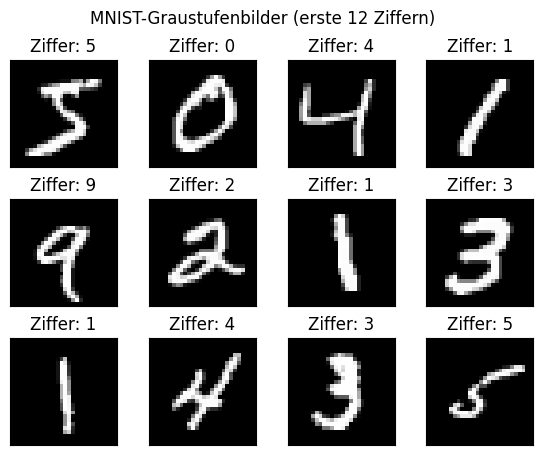

In [44]:
# Die Ersten 12 Elemente plotten

fig, axes = plt.subplots(
    3, 4, 
    figsize=(7, 5),
    gridspec_kw={"hspace": 0.3, "wspace": 0.1}, # Angaben in Prozent
    sharex = True,
    sharey = True
) 


for ax, element in zip(axes.reshape(-1), (np.arange(0,12))):
    ax.imshow(x_train[element], cmap="grey")  # Erstes Bild
    ax.set_title(f"Ziffer: {y_train[element]}")
    ax.set_xticks([])
    ax.set_yticks([])

fig.suptitle("MNIST-Graustufenbilder (erste 12 Ziffern)")
plt.savefig("Graustufenbilder.jpeg")
plt.show()


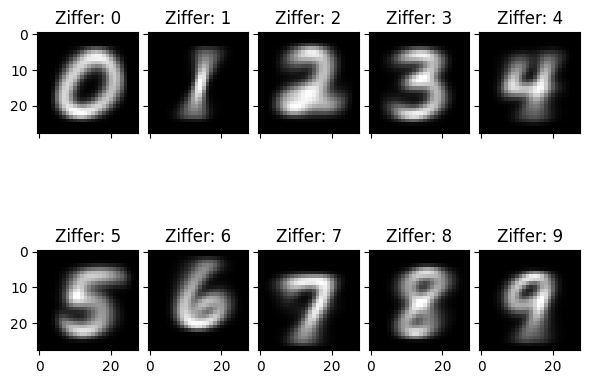

In [25]:
# Durschnittsbilder

__, axes = plt.subplots(
    2, 5, 
    figsize=(7, 5),
    gridspec_kw={"hspace": 0.3, "wspace": 0.1}, # Angaben in Prozent
    sharex = True,
    sharey = True
) 


for ax, element in zip(axes.reshape(-1), (np.arange(0,10))):
    mean_image = x_train[y_train == element].mean(axis=0)
    ax.imshow(mean_image, cmap="grey")  # Erstes Bild
    ax.set_title(f"Ziffer: {element}")
# ax[::-1].axis("off")
plt.show()


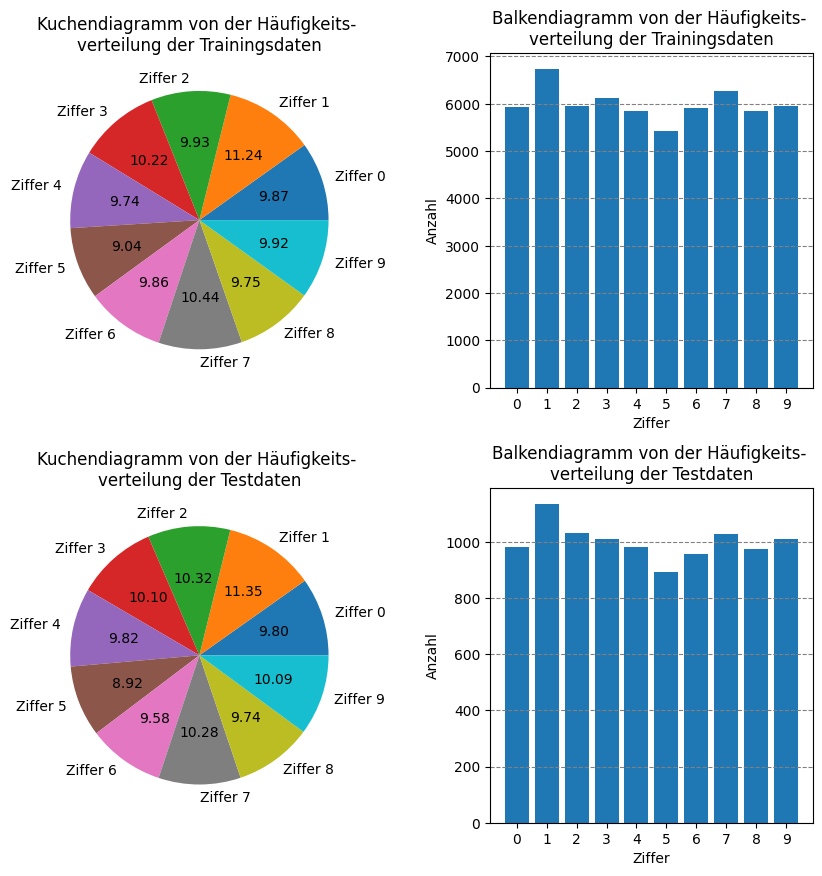

In [26]:
# Visualisierungen der Häufigkeiten von y_test und y_train

# Konvertierungen der Ergebnisse in ein np.array
value_counts = np.array(value_counts)

# Visualisierungen
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(
    2, 2, 
    figsize=(10, 10),
    gridspec_kw={"hspace": 0.3, "wspace": 0.4}, # Angaben in Prozent
) 

ax1.pie(value_counts[:, 1], labels = [f"Ziffer {int(x)}" for x in value_counts[:, 0]], autopct='%.2f');
ax1.set_title("Kuchendiagramm von der Häufigkeits- \nverteilung der Trainingsdaten");


ax2.bar([f"{int(x)}" for x in value_counts[:, 0]], height = value_counts[:, 1]);
ax2.set_title("Balkendiagramm von der Häufigkeits- \nverteilung der Trainingsdaten");
ax2.set_xlabel("Ziffer")
ax2.set_ylabel("Anzahl")
ax2.grid(which="major", axis="y", linestyle="--", zorder=-1, color="grey") 
ax2.set_xticks(
    ax2.get_xticks(),
    ax2.get_xticklabels(),
    rotation=0,
)

ax3.pie(value_counts[:, 3], labels = [f"Ziffer {int(x)}" for x in value_counts[:, 0]], autopct='%.2f');
ax3.set_title("Kuchendiagramm von der Häufigkeits- \nverteilung der Testdaten");

ax4.bar([f"{int(x)}" for x in value_counts[:, 0]], height = value_counts[:, 3]);
ax4.set_title("Balkendiagramm von der Häufigkeits- \nverteilung der Testdaten");
ax4.set_xlabel("Ziffer")
ax4.set_ylabel("Anzahl")
ax4.grid(which="major", axis="y", linestyle="--", zorder=-1, color="grey") 
ax4.set_xticks(
    ax4.get_xticks(),
    ax4.get_xticklabels(),
    rotation=0,
);

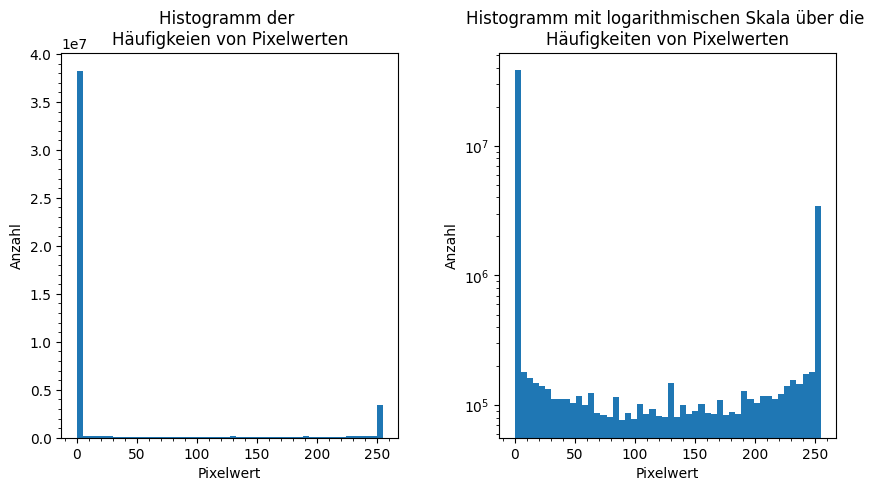

In [27]:
# Verteilung der Bilder mittels Histogramm anschauen

fig, (ax1, ax2) = plt.subplots(
    1, 2, 
    figsize=(10, 5),
    gridspec_kw={"hspace": 0.3, "wspace": 0.3},
)

# Histogramm über die Verteilung
ax1.hist(x_train.reshape(-1, 1), density=False, bins=50) 
ax1.set_title("Histogramm der \nHäufigkeien von Pixelwerten")
ax1.set_xlabel("Pixelwert")
ax1.set_ylabel("Anzahl") 
ax1.minorticks_on()

# Mit der logarithmischen Skala
ax2.hist(x_train.reshape(-1, 1), density=False, bins=50, log = True) 
ax2.set_title("Histogramm mit logarithmischen Skala über die \nHäufigkeiten von Pixelwerten")
ax2.set_xlabel("Pixelwert")
ax2.set_ylabel("Anzahl") 
ax2.minorticks_on()
# ax2.ticklabel_format(style='plain', axis='y')

Text(0.5, 1.0, 'Visualisierung der zweiten Ziffer')

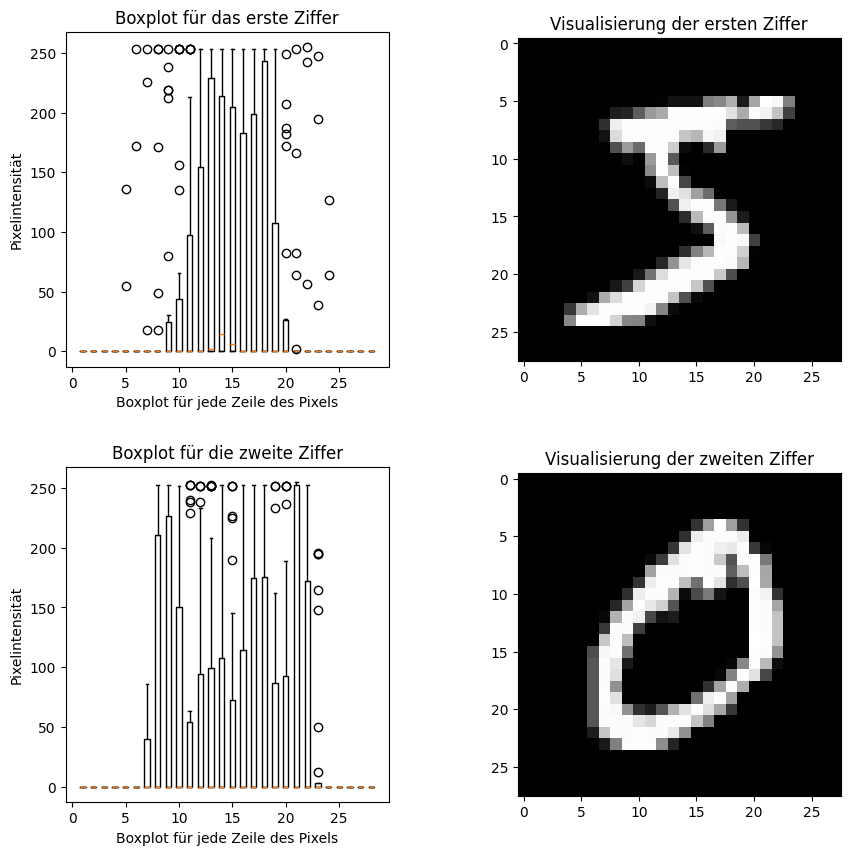

In [28]:
# Boxplots, um Ausreißer zu visualiseren und festzustellen
# Hohe Boxplot-Werte (Median/Outlier >127) korrespondieren direkt mit hellen Pixeln (weiße/helle Farben in Heatmaps/Bildern), niedrige mit dunklen (schwarze Bereiche).

fig, ((ax1, ax2), (ax3, ax4))  = plt.subplots(
    2, 2, 
    figsize=(10, 10),
    gridspec_kw={"hspace": 0.3, "wspace": 0.4}, # Angaben in Prozent
) 

ax1.boxplot(x_train[0], manage_ticks=False); # wird deutlich, dass die Pixelbilde so strukturiert sind, dass in den mittleren Spalten höhere Pixelwerte vorhanden sind; daher schlüssig und nicht als Ausreißer zu klassifizieren
ax1.set_title("Boxplot für das erste Ziffer") # erstes Bild
ax1.set_xlabel("Boxplot für jede Zeile des Pixels")
ax1.set_ylabel("Pixelintensität")

ax2.imshow(x_train[0], cmap="grey")
ax2.set_title("Visualisierung der ersten Ziffer") # erstes Bild

ax3.boxplot(x_train[1], manage_ticks=False);
ax3.set_title("Boxplot für die zweite Ziffer") # zweites Bild
ax3.set_xlabel("Boxplot für jede Zeile des Pixels")
ax3.set_ylabel("Pixelintensität")

ax4.imshow(x_train[1], cmap="grey")
ax4.set_title("Visualisierung der zweiten Ziffer") # zweites Bild


In [29]:
# überprüfen, wie Spalten und Zeilen aufgebaut sind

df_reshape

# testen, ob es Spalten und Zeilen gibt, die immer einen konstanten Wert zwischen 0 und 255 gibt
df_reshape.describe()

,0,1,2,3,4,5,6,7,8,9,...,774,775,776,777,778,779,780,781,782,783
count,60000.0,60000.0,60000.0,60000.0,60000.0,60000.0,60000.0,60000.0,60000.0,60000.0,...,60000.000000,60000.000000,60000.000000,60000.000000,60000.000000,60000.0000,60000.0,60000.0,60000.0,60000.0
mean,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.200433,0.088867,0.045633,0.019283,0.015117,0.0020,0.0,0.0,0.0,0.0
std,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,6.042472,3.956189,2.839845,1.686770,1.678283,0.3466,0.0,0.0,0.0,0.0
min,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.0000,0.0,0.0,0.0,0.0
25%,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.0000,0.0,0.0,0.0,0.0
50%,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.0000,0.0,0.0,0.0,0.0
75%,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.0000,0.0,0.0,0.0,0.0
max,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,254.000000,254.000000,253.000000,253.000000,254.000000,62.0000,0.0,0.0,0.0,0.0


In [30]:
# Dimensionsreduktion testen/überprüfen, da Laufzeit und Rechenzeit viel zeit in Anspruch nimmt; kann Overfitting vermeiden
# (Quelle siehe Logbuch)

# an x dimensionen reduziert
pca = PCA(n_components=0.95)
pca.fit(x_train.reshape(x_train.shape[0], -1))

# Anzahl erklärter Varianz 
pca.explained_variance_ratio_
cumsum = np.cumsum(pca.explained_variance_ratio_)
d = np.argmax(cumsum >= 0.95) + 1

# reduzieren
X_reduced_train = pca.fit_transform(x_train.reshape(x_train.shape[0], -1))
X_reduced_test = pca.transform(x_test.reshape(x_test.shape[0], -1))

# wieder in die alte Shape bringen
x_train_clean = pca.inverse_transform(X_reduced_train).reshape(-1, 28, 28)
x_test_clean = pca.inverse_transform(X_reduced_test).reshape(-1, 28, 28)

# Anzahl an Features
n_components = pca.n_components_
print("Anzahl PCA‑Features / Dimensionen:", n_components)

Anzahl PCA‑Features / Dimensionen: 154


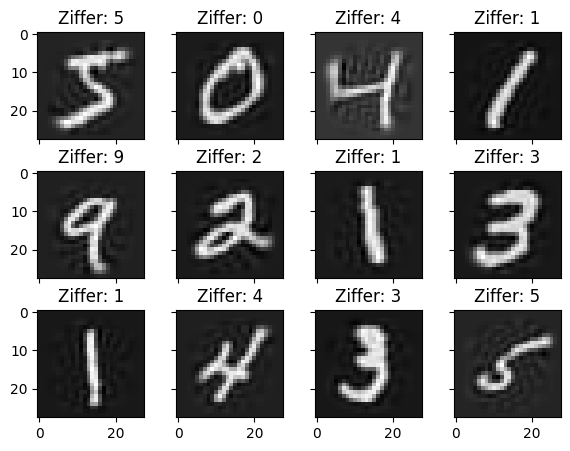

In [31]:
# Die Ersten 12 Elemente mit sauberen Daten plotten

__, axes = plt.subplots(
    3, 4, 
    figsize=(7, 5),
    gridspec_kw={"hspace": 0.3, "wspace": 0.1}, # Angaben in Prozent
    sharex = True,
    sharey = True
) 


for ax, element in zip(axes.reshape(-1), (np.arange(0,12))):
    ax.imshow(x_train_clean[element], cmap="grey")  # Erstes Bild
    ax.set_title(f"Ziffer: {y_train[element]}")
plt.show()


c:\Users\raxse\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\function_base.py:2897: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\Users\raxse\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\function_base.py:2898: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


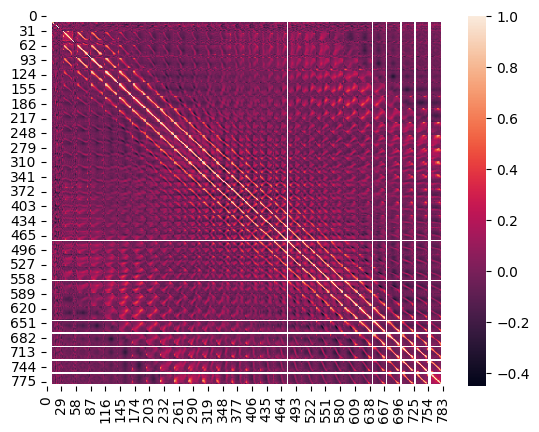

In [32]:
# Heatmap visualisieren; um zwischen Pixel Korrelationen zu überprüfen

corr = np.corrcoef(x_train_clean[0:10000 :, ].reshape(-1, (28*28)), rowvar=False) # ersten 10.000 elemente (weder am Anfang noch am Ende); Werte beziehen sich hier auf Spalten

sns.heatmap(corr);

### 3. Daten transformieren

In [33]:
# Daten werden transfomiert für die Weiterverarbeitung, auf einer weiteren Variable abgespeichert

scaler = StandardScaler()
x_train_clean = scaler.fit_transform(x_train_clean.reshape(-1, (28*28)).astype(np.float32))
x_test_clean = scaler.transform(x_test_clean.reshape(-1, (28*28)).astype(np.float32))


#### 4. Modell trainieren

##### 4.1 Modell ohne Tuning

In [34]:
# Log Reg

# Modell initiieren 
clf = LogisticRegression(max_iter=3000, random_state=42) 

# Daten fitten
clf.fit(x_train_clean, y_train) 


# koeffizienten
print(clf.coef_)

# score printen
acc = clf.score(x_train_clean, y_train)
print(f"Accuracy: {acc}")


[[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]]
Accuracy: 0.9275333333333333


Text(0.5, 1.0, 'Gewichte der logistischen Regression')

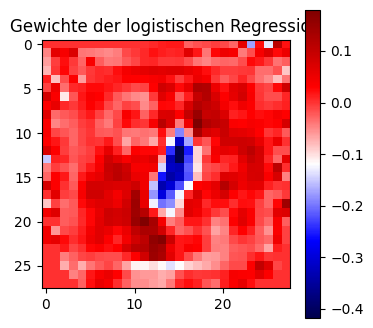

In [35]:
# Visualisierungen

# Gewichte printen
plt.figure(figsize=(4,4))
plt.imshow(clf.coef_[0].reshape(28,28), cmap="seismic")
plt.colorbar()
plt.title("Gewichte der logistischen Regression")


Evaluation auf Testdaten

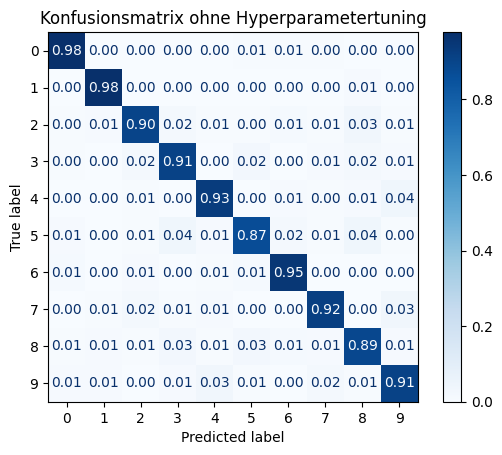

In [36]:
# Konfusionsmatrix auf Testdaten angewendet

y_pred = clf.predict(x_test_clean) 
cm_norm = confusion_matrix(y_test, y_pred, normalize='true')
disp = ConfusionMatrixDisplay(confusion_matrix=cm_norm, display_labels=np.arange(10))
disp.plot(cmap='Blues', values_format='.2f')  
plt.title('Konfusionsmatrix ohne Hyperparametertuning')
plt.savefig('Konfusionsmatrix ohne Hyperparametertuning.jpeg')
plt.show()

##### 4.2 Modell mit Kreuzvalidierung:

In [37]:
# Mit Kreuvalidierung


# Parameter definieren
param_grid = [ 
    # Keine Regularisierung 
    {
        'penalty': [None],
        'max_iter': [3000],
        # C wird bei penalty=None ignoriert
        'tol': [1e-4, 1e-3] 
    },
    
    # L2-Regularisierung 
    {
        'penalty': ['l2'],
        'C': [0.1, 1, 10],
        'max_iter': [3000],
        'tol': [1e-4, 1e-3] 
    },

]

# Modell initiieren 
clf = LogisticRegression()

# Grid definieren und fitten
grid = GridSearchCV(clf, param_grid=param_grid, cv=3, n_jobs=-1, verbose=1) 
grid.fit(x_train_clean, y_train)

 # Beste Parameter ausgeben
print("Besten Parameter:", grid.best_params_)
print("Bestes CV Ergebnis:", grid.best_score_)

final_model = grid.best_estimator_
print("Final Train:", final_model.score(x_train_clean, y_train))

Fitting 3 folds for each of 8 candidates, totalling 24 fits


c:\Users\raxse\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


Besten Parameter: {'C': 0.1, 'max_iter': 3000, 'penalty': 'l2', 'tol': 0.0001}
Bestes CV Ergebnis: 0.9177166666666666
Final Train: 0.92725


##### 4.1 Evaluation des Testmodells

number of iterations: [163]


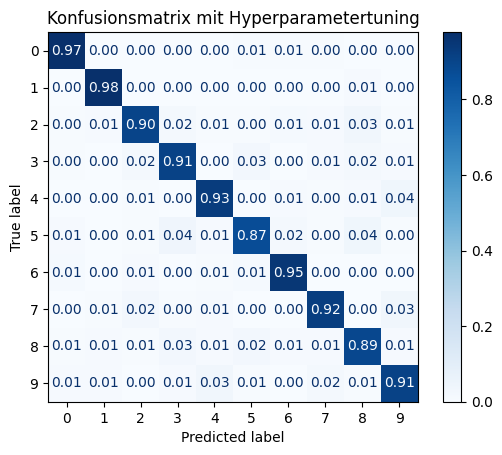

In [38]:
# Konfusionsmatrix

y_pred_test = final_model.predict(x_test_clean)
y_pred_train = final_model.predict(x_train_clean) # für tabelle später


print("number of iterations:",final_model.n_iter_)
cm_norm = confusion_matrix(y_test, y_pred_test, normalize='true')
disp = ConfusionMatrixDisplay(confusion_matrix=cm_norm, display_labels=np.arange(10))
disp.plot(cmap='Blues', values_format='.2f')  
plt.title('Konfusionsmatrix mit Hyperparametertuning')
plt.savefig('Konfusionsmatrix mit Hyperparametertuning.jpeg')
plt.show()


In [39]:
# ROC Metrik für Traindaten bestimmen (benötigt für spätere Tabelle)

# classifier predicition probabilities
Y_prob = final_model.predict_proba(x_train_clean)

# leere Liste intiieren
roc_data_test = []

for i in range(0,10):

    # Berechnen von fpr, tpr, roc
    fpr, tpr, _ = metrics.roc_curve((y_train == i).astype(int), Y_prob[:, i])
    roc = metrics.auc(fpr, tpr)

    # roc in einer liste speichern
    roc_data_test.append(roc)

c:\Users\raxse\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


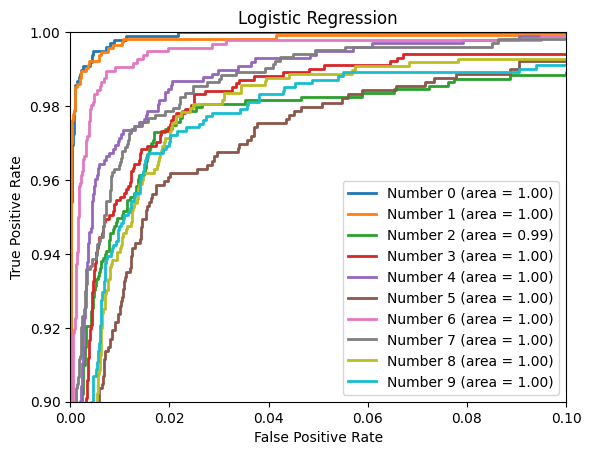

In [40]:
# roc kurve

# fit modell
final_model.fit(x_test_clean, y_test)

# classifier predicition probabilities
Y_prob_clean = grid.best_estimator_.predict_proba(x_test_clean)

# leere Liste intiieren
roc_data_clean = []

for i in range(0,10):

    # Berechnen von fpr, tpr, roc
    fpr, tpr, _ = metrics.roc_curve((y_test == i).astype(int), Y_prob_clean[:, i])
    roc = metrics.auc(fpr, tpr)

    # alles in einem plot plotten
    plt.plot(fpr, tpr, lw=2, label=f"Number {i} (area = %0.2f)" % roc)

    # ROC Werte für Ziffern in einer Liste speichern
    roc_data_clean.append(roc)

plt.plot([0, 1], [0, 1], color="darkblue", lw=2, linestyle="--")
plt.xlim([0, 0.1])  # Fokus auf kleinen FPR-Bereich
plt.ylim([0.9, 1.0])  # Fokus auf hohem TPR-Bereich
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Logistic Regression")
plt.legend(loc="lower right")
plt.show()

In [41]:
# Klassifikationsreport, um Güte des Modells zu bestimmen

print(classification_report(y_test, y_pred_test))


              precision    recall  f1-score   support

           0       0.95      0.97      0.96       980
           1       0.96      0.98      0.97      1135
           2       0.92      0.90      0.91      1032
           3       0.90      0.91      0.90      1010
           4       0.92      0.93      0.93       982
           5       0.90      0.87      0.89       892
           6       0.94      0.95      0.95       958
           7       0.94      0.92      0.93      1028
           8       0.88      0.89      0.89       974
           9       0.90      0.91      0.91      1009

    accuracy                           0.92     10000
   macro avg       0.92      0.92      0.92     10000
weighted avg       0.92      0.92      0.92     10000



In [42]:
# Tabelle für alle Modelle erstellen
results = pd.DataFrame({
    "Model": [
        'Full Train', 
        'Test'
    ],

    'Dataset': [ 
        len(x_train_clean), 
        len(x_test_clean)
    ],

    'Accuracy': [
        accuracy_score(y_train, y_pred_train),
        accuracy_score(y_test, y_pred_test)
    ],

    'AUC': [
        np.mean(roc_data_clean),
        np.mean(roc_data_test),
    ],

    'F1-Macro': [
        f1_score(y_train, y_pred_train, average='macro'),
        f1_score(y_test, y_pred_test, average='macro')
    ]
})

results

,Model,Dataset,Accuracy,AUC,F1-Macro
0,Full Train,60000,0.92725,0.997662,0.926199
1,Test,10000,0.92360,0.994279,0.922532


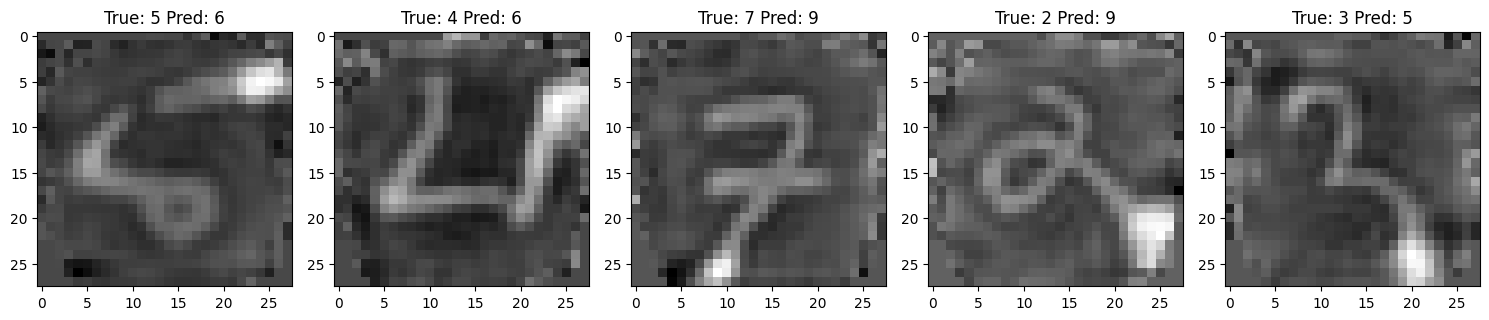

In [43]:

# Falsch klassifizierte Bilder
wrong_idx = np.where(y_test != final_model.predict(x_test_clean))[0]

fig, axes = plt.subplots(1, 5, figsize=(15,3))

for ax, idx in zip(axes, wrong_idx[:5]):
    true_class = y_test[idx]

    # Prediction pro Bild
    img_flat = x_test_clean[idx].reshape(1,-1)
    pred_class = final_model.predict(img_flat)[0]

    img = x_test_clean[idx].reshape(28,28)
    ax.imshow(img, cmap='gray')
    ax.set_title(f'True: {true_class} Pred: {pred_class}')
    
plt.tight_layout()
plt.show()